In [9]:

# ============================================================
# 14A — ROBUST REGRESSION FOR ANEMOMETER SCREENING
# Run this cell FIRST.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import HuberRegressor
from IPython.display import display

ROOT14 = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

TARGET14 = "WTG170"

# Match the original 08 generating-power restriction.
# Set False only as a documented sensitivity analysis.
POWER_FILTER14 = False

SCADA_FILE14 = (
    ROOT14
    / "data/processed/12_farmwide_wake_exposure"
    / "scada_wake_comparison"
    / "ALTA10_SCADA_with_wake_categories.parquet"
)

# ------------------------------------------------------------
# 1. Load previous fixed peer selections and evaluation split
# ------------------------------------------------------------

RUNS14 = sorted(
    p for p in (
        ROOT14 / "data/processed/08_scada_screening"
    ).glob("run_*")
    if (p / "08_fixed_peers.csv").is_file()
    and (p / "08_run_settings.json").is_file()
)

if not RUNS14 or not SCADA_FILE14.is_file():
    raise FileNotFoundError(
        "Need Dataset 1 and a completed Notebook 08 run."
    )

RUN08_14 = RUNS14[-1]

peer_table14 = pd.read_csv(
    RUN08_14 / "08_fixed_peers.csv"
)

peers14 = (
    peer_table14.loc[
        peer_table14.turbine.eq(TARGET14)
    ]
    .sort_values("rank")
    .peer.tolist()
)

if len(peers14) != 3 or len(set(peers14)) != 3:
    raise ValueError(
        f"{TARGET14} needs three distinct fixed peers: {peers14}"
    )

with open(
    RUN08_14 / "08_run_settings.json",
    encoding="utf-8"
) as f:
    settings14 = json.load(f)

SPLIT14 = pd.to_datetime(
    settings14["evaluation_start_utc"],
    utc=True
)

# ------------------------------------------------------------
# 2. Load SCADA and wake measurements
# ------------------------------------------------------------

columns14 = [
    "timestamp",
    "turbine",
    "wind_speed",
    "real_power_ac",
    "air_density",
    "mast_wind_speed_ms",
    "mast_wind_from_deg",
    "jensen_wake_category"
]

d14 = pd.read_parquet(
    SCADA_FILE14,
    columns=columns14
)

d14 = d14.loc[
    d14.turbine.isin([TARGET14] + peers14)
].copy()

d14["timestamp"] = pd.to_datetime(
    d14.timestamp,
    utc=True,
    errors="coerce"
)

if (
    d14.timestamp.isna().any()
    or d14.duplicated(["timestamp", "turbine"]).any()
):
    raise ValueError("Invalid or duplicate SCADA timestamps.")

for col in [
    "wind_speed",
    "real_power_ac",
    "air_density",
    "mast_wind_speed_ms",
    "mast_wind_from_deg"
]:
    d14[col] = pd.to_numeric(
        d14[col],
        errors="coerce"
    )

d14["jensen_wake_category"] = (
    d14.jensen_wake_category
    .astype("string")
    .str.upper()
)

target14 = (
    d14.loc[d14.turbine.eq(TARGET14)]
    .set_index("timestamp")
    .sort_index()
)

peer_rows14 = d14.loc[
    d14.turbine.isin(peers14)
]

def peer_matrix14(column):
    return (
        peer_rows14
        .pivot(
            index="timestamp",
            columns="turbine",
            values=column
        )
        .reindex(
            index=target14.index,
            columns=peers14
        )
    )

p_wind14 = peer_matrix14("wind_speed")
p_power14 = peer_matrix14("real_power_ac")
p_wake14 = peer_matrix14("jensen_wake_category")

# ------------------------------------------------------------
# 3. Restrict to simultaneous low-wake conditions
# ------------------------------------------------------------

eligible14 = (
    target14.wind_speed.between(3, 25)
    & p_wind14.ge(3).all(axis=1)
    & p_wind14.le(25).all(axis=1)
    & target14.mast_wind_speed_ms.between(7, 10)
    & target14.mast_wind_from_deg.between(0, 360)
    & target14.jensen_wake_category.eq("LOW")
    & p_wake14.eq("LOW").all(axis=1)
)

if POWER_FILTER14:
    eligible14 &= (
        target14.real_power_ac.between(100, 2850)
        & p_power14.ge(100).all(axis=1)
        & p_power14.le(2850).all(axis=1)
    )

sample14 = pd.DataFrame(index=target14.index)

sample14["mast_ms"] = target14.mast_wind_speed_ms
sample14["direction_deg"] = (
    target14.mast_wind_from_deg.mod(360)
)

sample14["peer_median_ms"] = (
    p_wind14.median(axis=1, skipna=False)
)

sample14["target_ms"] = target14.wind_speed

sample14["difference_ms"] = (
    sample14.target_ms - sample14.peer_median_ms
)

sample14 = (
    sample14.loc[eligible14]
    .dropna()
    .sort_index()
    .copy()
)

sample14["day"] = sample14.index.floor("D")

sample14["sector"] = (
    ((sample14.direction_deg + 15) % 360) // 30
).astype(int)

angle14 = np.deg2rad(sample14.direction_deg)

sample14["speed_sq"] = sample14.mast_ms**2
sample14["sin_dir"] = np.sin(angle14)
sample14["cos_dir"] = np.cos(angle14)
sample14["sin2_dir"] = np.sin(2 * angle14)
sample14["cos2_dir"] = np.cos(2 * angle14)

# ------------------------------------------------------------
# 4. Earlier training vs later evaluation
# ------------------------------------------------------------

past14 = sample14.loc[
    sample14.index < SPLIT14
].copy()

future14 = sample14.loc[
    sample14.index >= SPLIT14
].copy()

sector_support14 = (
    past14.groupby("sector")
    .agg(
        n=("difference_ms", "size"),
        days=("day", "nunique")
    )
)

supported_sectors14 = sector_support14.index[
    (sector_support14.n >= 30)
    & (sector_support14.days >= 5)
]

train14 = past14.loc[
    past14.sector.isin(supported_sectors14)
].copy()

eval14 = future14.loc[
    future14.sector.isin(supported_sectors14)
].copy()

# Avoid extrapolation outside earlier mast-speed coverage.
if not train14.empty:
    eval14 = eval14.loc[
        eval14.mast_ms.between(
            train14.mast_ms.min(),
            train14.mast_ms.max()
        )
    ].copy()

if (
    len(train14) < 100
    or train14.day.nunique() < 10
    or len(eval14) < 30
    or eval14.day.nunique() < 5
):
    raise ValueError(
        f"Insufficient comparable observations for {TARGET14}: "
        f"train={len(train14)}, evaluation={len(eval14)}. "
        "POWER_FILTER14=False is an optional sensitivity check."
    )

OUT14 = (
    ROOT14
    / "data/processed/14_statistical_model_validation"
    / (
        f"{TARGET14}_run_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%S%fZ"
        )
    )
)

OUT14.mkdir(parents=True, exist_ok=False)

# ------------------------------------------------------------
# 5. Shared scoring and plotting functions
# ------------------------------------------------------------

def score14(name, pred_train, pred_eval):

    early_resid = (
        train14.difference_ms.to_numpy()
        - np.asarray(pred_train)
    )

    center = float(np.median(early_resid))

    mad = float(
        np.median(np.abs(early_resid - center))
    )

    threshold = max(
        1.0,
        3 * 1.4826 * mad
    )

    result = eval14[
        [
            "target_ms",
            "peer_median_ms",
            "mast_ms",
            "direction_deg",
            "difference_ms"
        ]
    ].copy()

    result["predicted_difference_ms"] = pred_eval

    result["residual_ms"] = (
        result.difference_ms
        - result.predicted_difference_ms
        - center
    )

    result["single_flag"] = (
        result.residual_ms.abs() > threshold
    )

    result["sustained_flag"] = False

    # Break episodes at gaps, threshold changes,
    # or changes in residual direction.
    breaks = (
        result.index.to_series()
        .diff()
        .ne(pd.Timedelta(minutes=10))
        | result.single_flag.ne(
            result.single_flag.shift(fill_value=False)
        )
        | np.sign(result.residual_ms).ne(
            np.sign(result.residual_ms.shift(fill_value=0))
        )
    )

    groups = breaks.cumsum()
    event_rows = []

    for _, g in result.loc[
        result.single_flag
    ].groupby(groups[result.single_flag]):

        if len(g) < 3:
            continue

        result.loc[g.index, "sustained_flag"] = True

        event_rows.append({
            "first_utc": str(g.index.min()),
            "last_label_utc": str(g.index.max()),
            "records": len(g),
            "nominal_minutes": 10 * len(g),
            "direction": (
                "above_expected"
                if g.residual_ms.mean() > 0
                else "below_expected"
            ),
            "mean_residual_ms": g.residual_ms.mean(),
            "mean_target_minus_peers_ms":
                g.difference_ms.mean()
        })

    events = pd.DataFrame(event_rows)

    errors = (
        result.difference_ms
        - result.predicted_difference_ms
    )

    summary = {
        "model": name,
        "train_n": len(train14),
        "eval_n": len(eval14),
        "eval_days": int(eval14.day.nunique()),
        "mae_ms": float(errors.abs().mean()),
        "rmse_ms": float(np.sqrt(np.mean(errors**2))),
        "exploratory_threshold_ms": threshold,
        "sustained_episodes": len(events),
        "sustained_minutes":
            int(result.sustained_flag.sum() * 10)
    }

    result.reset_index().to_csv(
        OUT14 / f"{name}_evaluation_intervals.csv",
        index=False
    )

    events.to_csv(
        OUT14 / f"{name}_sustained_episodes.csv",
        index=False
    )

    return result, summary, events


def plot14(result, title, filename, threshold):

    fig, axs = plt.subplots(
        2, 1,
        figsize=(12, 7),
        sharex=True
    )

    axs[0].plot(
        result.index,
        result.difference_ms,
        ".",
        ms=2,
        label="Observed SCADA − peer median"
    )

    axs[0].plot(
        result.index,
        result.predicted_difference_ms,
        linewidth=1,
        label="Predicted difference"
    )

    axs[0].set_ylabel("Wind-speed difference (m/s)")
    axs[0].legend()

    axs[1].plot(
        result.index,
        result.residual_ms,
        ".",
        ms=2,
        label="Evaluation residual"
    )

    for value in [-threshold, threshold]:
        axs[1].axhline(
            value,
            linestyle="--",
            color="tab:red"
        )

    flagged = result.loc[result.sustained_flag]

    axs[1].scatter(
        flagged.index,
        flagged.residual_ms,
        s=12,
        label="Sustained candidate"
    )

    axs[1].set_ylabel("Unexplained difference (m/s)")
    axs[1].set_xlabel("UTC timestamp")
    axs[1].legend()

    fig.suptitle(title)

    for ax in axs:
        ax.grid(alpha=0.2)

    fig.tight_layout()

    fig.savefig(
        OUT14 / filename,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 6. Fit Huber robust regression
# ------------------------------------------------------------

HUBER_COLS14 = [
    "mast_ms",
    "speed_sq",
    "sin_dir",
    "cos_dir"
]

huber14 = make_pipeline(
    StandardScaler(),
    HuberRegressor(
        alpha=0.01,
        epsilon=1.35,
        max_iter=1000
    )
)

huber14.fit(
    train14[HUBER_COLS14],
    train14.difference_ms
)

robust_eval14, robust_summary14, robust_events14 = score14(
    "14A_robust",
    huber14.predict(train14[HUBER_COLS14]),
    huber14.predict(eval14[HUBER_COLS14])
)

plot14(
    robust_eval14,
    f"{TARGET14} — Huber robust regression",
    "14A_robust_observed_predicted_residual.png",
    robust_summary14["exploratory_threshold_ms"]
)

print("Target:", TARGET14)
print("Fixed peers:", peers14)
print("Evaluation starts:", SPLIT14)
print("Jointly low-wake records:", len(sample14))
print("Training records:", len(train14))
print("Evaluation records:", len(eval14))

display(
    pd.DataFrame([robust_summary14]).round(3)
)

print("\nSUSTAINED CANDIDATE EPISODES")
display(robust_events14.head(15).round(3))

print("\nSaved to:", OUT14)


ValueError: Insufficient comparable observations for WTG170: train=0, evaluation=0. POWER_FILTER14=False is an optional sensitivity check.

In [10]:

# ============================================================
# WTG170 — IDENTIFY WHY REGRESSION HAS ZERO OBSERVATIONS
# Run after the failed Cell 14A.
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

idx = target14.index

def clean_mask(s):
    return (
        s.reindex(idx)
        .fillna(False)
        .astype(bool)
    )

# Individual screening conditions
checks = {
    "WTG170 valid SCADA wind": clean_mask(
        target14.wind_speed.between(3, 25)
    ),

    "All 3 peers valid SCADA wind": clean_mask(
        p_wind14.ge(3).all(axis=1)
        & p_wind14.le(25).all(axis=1)
    ),

    "Mast wind 7-10 m/s": clean_mask(
        target14.mast_wind_speed_ms.between(7, 10)
    ),

    "Valid mast direction": clean_mask(
        target14.mast_wind_from_deg.between(0, 360)
    ),

    "WTG170 LOW Jensen wake": clean_mask(
        target14.jensen_wake_category
        .astype("string").str.upper().eq("LOW")
    ),

    "All 3 peers LOW Jensen wake": clean_mask(
        p_wake14.astype("string")
        .apply(lambda s: s.str.upper())
        .eq("LOW").all(axis=1)
    )
}

remaining = pd.Series(True, index=idx)
rows = []

for name, condition in checks.items():

    remaining &= condition

    rows.append({
        "Filter applied": name,
        "Remaining total": int(remaining.sum()),
        "Earlier training": int(
            (remaining & (idx < SPLIT14)).sum()
        ),
        "Later evaluation": int(
            (remaining & (idx >= SPLIT14)).sum()
        )
    })

print("WTG170 — FILTER-BY-FILTER COVERAGE")
print("Fixed peers:", peers14)
print("Power filter currently enabled:", POWER_FILTER14)

display(pd.DataFrame(rows))

# Separate power check — without silently changing sample
wind_wake_mask = remaining.copy()

power_ok = (
    target14.real_power_ac.between(100, 2850)
    & p_power14.ge(100).all(axis=1)
    & p_power14.le(2850).all(axis=1)
)

after_power = wind_wake_mask & clean_mask(power_ok)

print("\nJOINT LOW-WAKE COVERAGE:")
print("Before power:", int(wind_wake_mask.sum()))
print("After power:", int(after_power.sum()))

# Identify which individual peer restricts low-wake coverage
before_wake = (
    checks["WTG170 valid SCADA wind"]
    & checks["All 3 peers valid SCADA wind"]
    & checks["Mast wind 7-10 m/s"]
    & checks["Valid mast direction"]
)

peer_rows = []

for peer in peers14:

    peer_low = clean_mask(
        p_wake14[peer]
        .astype("string")
        .str.upper()
        .eq("LOW")
    )

    peer_rows.append({
        "Turbine": peer,
        "Comparable wind records": int(before_wake.sum()),
        "LOW wake records": int(
            (before_wake & peer_low).sum()
        )
    })

display(pd.DataFrame(peer_rows))

# Check wind-direction training support after all filters
final_mask = (
    after_power if POWER_FILTER14
    else wind_wake_mask
)

sector = (
    (target14.mast_wind_from_deg + 15) % 360 // 30
)

early = final_mask & (idx < SPLIT14)

sector_data = pd.DataFrame({
    "sector": sector.loc[early].to_numpy(),
    "day": idx[early].floor("D")
})

if len(sector_data):

    sector_counts = (
        sector_data.groupby("sector")
        .agg(
            observations=("day", "size"),
            days=("day", "nunique")
        )
    )

    sector_counts["supported"] = (
        sector_counts.observations.ge(30)
        & sector_counts.days.ge(5)
    )

    print("\nEARLIER TRAINING SUPPORT BY DIRECTION")
    display(sector_counts)

else:
    print("\nNo earlier observations survive all active filters.")

print("\nDiagnostic complete.")


WTG170 — FILTER-BY-FILTER COVERAGE
Fixed peers: ['WTG171', 'WTG169', 'WTG172']
Power filter currently enabled: False


,Filter applied,Remaining total,Earlier training,Later evaluation
0,WTG170 valid SCADA wind,33656,25586,8070
1,All 3 peers valid SCADA wind,448,448,0
2,Mast wind 7-10 m/s,137,137,0
3,Valid mast direction,137,137,0
4,WTG170 LOW Jensen wake,77,77,0
5,All 3 peers LOW Jensen wake,44,44,0



JOINT LOW-WAKE COVERAGE:
Before power: 44
After power: 27


,Turbine,Comparable wind records,LOW wake records
0,WTG171,137,83
1,WTG169,137,44
2,WTG172,137,86



EARLIER TRAINING SUPPORT BY DIRECTION


,observations,days,supported
sector,,,
10.0,42,2,False
11.0,2,2,False



Diagnostic complete.


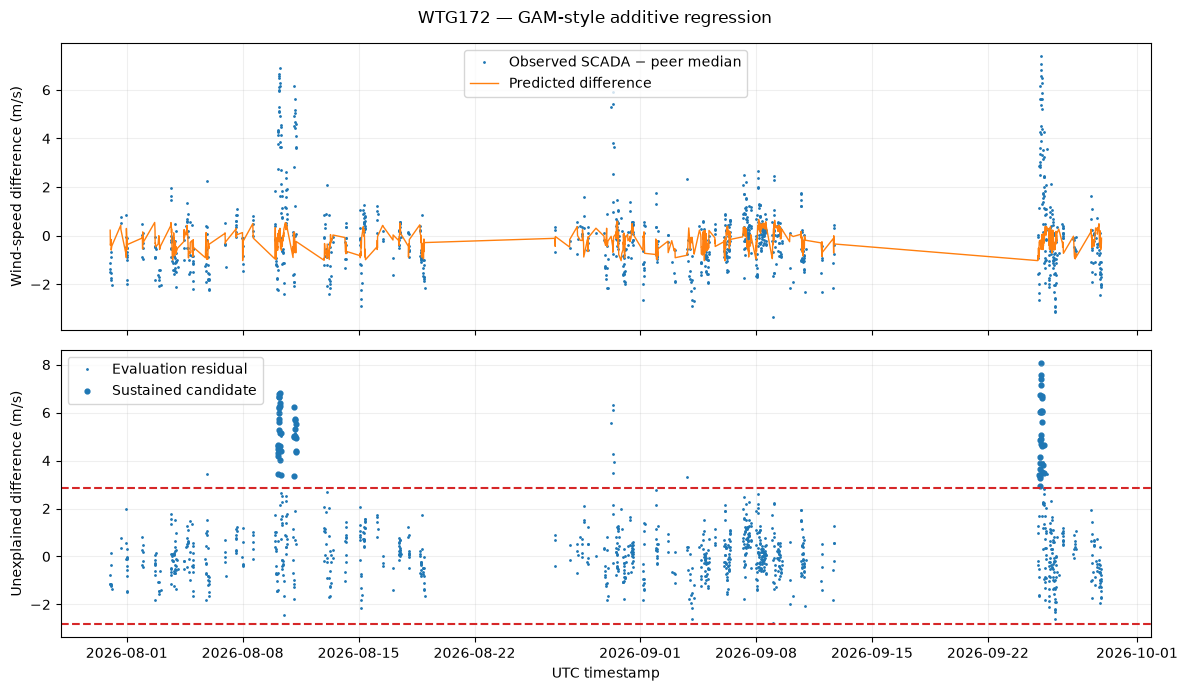


ROBUST REGRESSION VS GAM-STYLE REGRESSION
Same evaluation observations: 1087


,model,train_n,eval_n,eval_days,mae_ms,rmse_ms,exploratory_threshold_ms,sustained_episodes,sustained_minutes
0,14A_robust,2189,1087,41,1.063,1.667,2.782,7,650
1,14B_GAM_style,2189,1087,41,1.072,1.638,2.834,7,650



GAM SUSTAINED CANDIDATE EPISODES


,first_utc,last_label_utc,records,nominal_minutes,direction,mean_residual_ms,mean_target_minus_peers_ms
0,2026-08-10 03:00:00+00:00,2026-08-10 05:30:00+00:00,16,160,above_expected,5.440,5.186
1,2026-08-10 06:00:00+00:00,2026-08-10 06:30:00+00:00,4,40,above_expected,5.590,5.434
2,2026-08-10 06:50:00+00:00,2026-08-10 07:20:00+00:00,4,40,above_expected,4.389,3.689
3,2026-08-11 02:30:00+00:00,2026-08-11 03:40:00+00:00,8,80,above_expected,5.175,4.841
4,2026-08-11 04:40:00+00:00,2026-08-11 05:10:00+00:00,4,40,above_expected,4.810,3.983
5,2026-09-25 02:40:00+00:00,2026-09-25 06:50:00+00:00,26,260,above_expected,5.317,4.839
6,2026-09-25 08:30:00+00:00,2026-09-25 08:50:00+00:00,3,30,above_expected,3.985,3.561



Saved to: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\14_statistical_model_validation\WTG172_run_20261103T183320011829Z


In [2]:

# ============================================================
# 14B — GAM-STYLE ADDITIVE REGRESSION
# Run AFTER Cell 14A.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import Ridge
from IPython.display import display

# ------------------------------------------------------------
# 1. Build smooth wind-speed terms
# ------------------------------------------------------------

speed_spline14 = SplineTransformer(
    n_knots=6,
    degree=3,
    include_bias=False
)

speed_spline14.fit(
    train14[["mast_ms"]].to_numpy()
)

def gam_matrix14(frame):

    speed_terms = speed_spline14.transform(
        frame[["mast_ms"]].to_numpy()
    )

    # Periodic direction terms respect the 0°/360° boundary.
    direction_terms = frame[
        [
            "sin_dir",
            "cos_dir",
            "sin2_dir",
            "cos2_dir"
        ]
    ].to_numpy()

    return np.column_stack([
        speed_terms,
        direction_terms
    ])

# ------------------------------------------------------------
# 2. Fit the additive regression
# ------------------------------------------------------------

gam14 = Ridge(
    alpha=5.0
)

gam14.fit(
    gam_matrix14(train14),
    train14.difference_ms
)

# ------------------------------------------------------------
# 3. Evaluate on the same later observations
# ------------------------------------------------------------

gam_eval14, gam_summary14, gam_events14 = score14(
    "14B_GAM_style",
    gam14.predict(
        gam_matrix14(train14)
    ),
    gam14.predict(
        gam_matrix14(eval14)
    )
)

plot14(
    gam_eval14,
    f"{TARGET14} — GAM-style additive regression",
    "14B_GAM_observed_predicted_residual.png",
    gam_summary14["exploratory_threshold_ms"]
)

# ------------------------------------------------------------
# 4. Compare both statistical models
# ------------------------------------------------------------

comparison14 = pd.DataFrame([
    robust_summary14,
    gam_summary14
])

comparison14.to_csv(
    OUT14 / "14A_vs_14B_model_comparison.csv",
    index=False
)

print("\nROBUST REGRESSION VS GAM-STYLE REGRESSION")
print("Same evaluation observations:", len(eval14))

display(comparison14.round(3))

print("\nGAM SUSTAINED CANDIDATE EPISODES")
display(gam_events14.head(15).round(3))

print("\nSaved to:", OUT14)


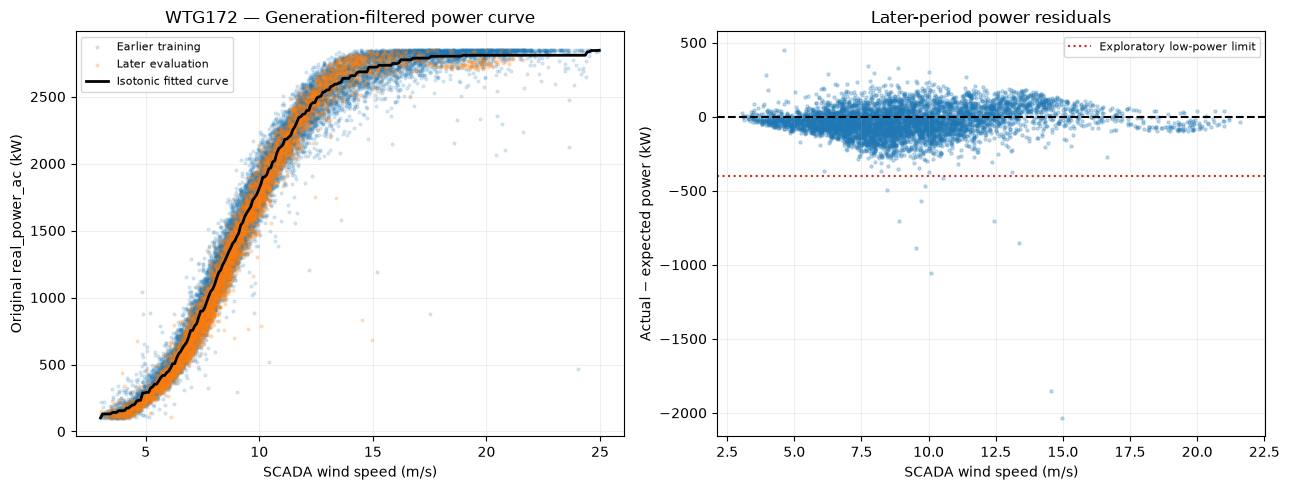


POWER-CURVE REGRESSION RESULTS
Turbine: WTG172
Training observations: 15540
Evaluation observations: 5196
Evaluation MAE: 79.40 kW
Evaluation RMSE: 108.98 kW
Unusually low-power observations: 11

Saved to: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\14_statistical_model_validation\WTG172_run_20261103T183320011829Z

Important: Power residuals may reflect curtailment, density, turbine operating state, or measurement processing. They do not independently verify anemometer accuracy.


In [5]:

# ============================================================
# 14C — POWER-CURVE REGRESSION
# Run AFTER Cell 14A.
# Uses original real_power_ac, not KPI substitutions.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression
from IPython.display import display

# ------------------------------------------------------------
# 1. Select valid generating observations
# ------------------------------------------------------------

power14 = target14.loc[
    target14.wind_speed.between(3, 25)
    & target14.real_power_ac.between(100, 2850)
    & target14.jensen_wake_category.eq("LOW")
    & target14.mast_wind_speed_ms.between(3, 25)
].copy().sort_index()

# Chronological train/evaluation split
power_train14 = power14.loc[
    power14.index < SPLIT14
].copy()

power_eval14 = power14.loc[
    power14.index >= SPLIT14
].copy()

# Exclude extrapolation outside the training wind-speed range
if len(power_train14):
    power_eval14 = power_eval14.loc[
        power_eval14.wind_speed.between(
            power_train14.wind_speed.min(),
            power_train14.wind_speed.max()
        )
    ].copy()

if (
    len(power_train14) < 150
    or power_train14.index.floor("D").nunique() < 10
    or len(power_eval14) < 30
):
    raise ValueError(
        f"Insufficient original power observations for {TARGET14}. "
        f"Training: {len(power_train14)}, "
        f"evaluation: {len(power_eval14)}. "
        "Do not replace missing original power with KPI zeros."
    )

# ------------------------------------------------------------
# 2. Fit nondecreasing power-curve regression
# ------------------------------------------------------------

power_model14 = IsotonicRegression(
    increasing=True,
    y_min=0,
    y_max=2850,
    out_of_bounds="clip"
)

power_model14.fit(
    power_train14.wind_speed.to_numpy(),
    power_train14.real_power_ac.to_numpy()
)

# ------------------------------------------------------------
# 3. Predict power and calculate residuals
# ------------------------------------------------------------

power_eval14["expected_power_kw"] = (
    power_model14.predict(
        power_eval14.wind_speed.to_numpy()
    )
)

power_eval14["power_residual_kw"] = (
    power_eval14.real_power_ac
    - power_eval14.expected_power_kw
)

training_power_residual = (
    power_train14.real_power_ac.to_numpy()
    - power_model14.predict(
        power_train14.wind_speed.to_numpy()
    )
)

center_power14 = np.median(
    training_power_residual
)

spread_power14 = (
    1.4826
    * np.median(
        np.abs(
            training_power_residual - center_power14
        )
    )
)

power_threshold14 = max(
    400.0,
    3 * spread_power14
)

# Exploratory low-power deviation, not a fault label.
power_eval14["unusually_low_power"] = (
    power_eval14.power_residual_kw - center_power14
    < -power_threshold14
)

# ------------------------------------------------------------
# 4. Evaluate the model
# ------------------------------------------------------------

power_mae14 = float(
    power_eval14.power_residual_kw.abs().mean()
)

power_rmse14 = float(
    np.sqrt(
        np.mean(
            power_eval14.power_residual_kw**2
        )
    )
)

power_eval14.reset_index().to_csv(
    OUT14 / "14C_power_curve_evaluation.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Plot the fitted power curve and residuals
# ------------------------------------------------------------

fig, axs = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

axs[0].scatter(
    power_train14.wind_speed,
    power_train14.real_power_ac,
    s=4,
    alpha=0.15,
    label="Earlier training"
)

axs[0].scatter(
    power_eval14.wind_speed,
    power_eval14.real_power_ac,
    s=4,
    alpha=0.2,
    label="Later evaluation"
)

wind_grid14 = np.linspace(
    power_train14.wind_speed.min(),
    power_train14.wind_speed.max(),
    250
)

axs[0].plot(
    wind_grid14,
    power_model14.predict(wind_grid14),
    color="black",
    linewidth=2,
    label="Isotonic fitted curve"
)

axs[0].set(
    xlabel="SCADA wind speed (m/s)",
    ylabel="Original real_power_ac (kW)",
    title=f"{TARGET14} — Generation-filtered power curve"
)

axs[0].legend(fontsize=8)

# Evaluation residuals
axs[1].scatter(
    power_eval14.wind_speed,
    power_eval14.power_residual_kw,
    s=5,
    alpha=0.25
)

axs[1].axhline(
    0,
    color="black",
    linestyle="--"
)

axs[1].axhline(
    center_power14 - power_threshold14,
    color="tab:red",
    linestyle=":",
    label="Exploratory low-power limit"
)

axs[1].set(
    xlabel="SCADA wind speed (m/s)",
    ylabel="Actual − expected power (kW)",
    title="Later-period power residuals"
)

axs[1].legend(fontsize=8)

for ax in axs:
    ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    OUT14 / "14C_power_curve_fit_and_residuals.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. Print final results
# ------------------------------------------------------------

print("\nPOWER-CURVE REGRESSION RESULTS")
print("Turbine:", TARGET14)
print("Training observations:", len(power_train14))
print("Evaluation observations:", len(power_eval14))
print(f"Evaluation MAE: {power_mae14:.2f} kW")
print(f"Evaluation RMSE: {power_rmse14:.2f} kW")

print(
    "Unusually low-power observations:",
    int(power_eval14.unusually_low_power.sum())
)

print("\nSaved to:", OUT14)

print(
    "\nImportant: Power residuals may reflect curtailment, "
    "density, turbine operating state, or measurement processing. "
    "They do not independently verify anemometer accuracy."
)


Target turbine: WTG172
Fixed comparison turbines: ['WTG171', 'WTG173', 'WTG170']
Evaluation begins: 2026-07-31 00:00:00+00:00

WTG172 — THREE-MODEL EVENT SUMMARY


,date,scada_records,huber_evaluated_n,gam_evaluated_n,both_models_positive_sustained_n,mean_target_minus_peers_wind_ms,mean_huber_residual_ms,mean_gam_residual_ms,original_power_available_on_flags_n,power_model_overlap_n,mean_power_curve_residual_kw,all_three_peer_power_overlap_n,mean_target_minus_peers_power_kw,target_power_higher_than_peers_pct
0,2026-08-10,144,70,70,24,4.98,5.30,5.29,24,24,-85.18,24,1489.53,100.0
1,2026-08-11,144,24,24,12,4.55,5.03,5.05,12,12,-58.72,12,1341.19,100.0
2,2026-09-25,144,112,112,29,4.71,5.14,5.18,29,29,-64.27,29,1419.63,100.0



JOINTLY FLAGGED POSITIVE WIND-SPEED OBSERVATIONS


,target_scada_ms,peer_median_wind_ms,target_minus_peers_wind_ms,huber_residual_ms,gam_residual_ms,target_original_power_kw,peer_median_power_kw,target_minus_peers_power_kw,model_expected_power_kw,model_power_residual_kw
timestamp,,,,,,,,,,
2026-08-10 03:00:00+00:00,8.90,6.16,2.74,3.26,3.45,1252.44,577.36,675.08,1410.80,-158.37
2026-08-10 03:10:00+00:00,10.48,6.33,4.16,4.30,4.30,1815.44,580.46,1234.99,1969.01,-153.57
2026-08-10 03:20:00+00:00,11.06,6.73,4.33,4.49,4.50,2016.11,653.14,1362.97,2158.41,-142.31
2026-08-10 03:30:00+00:00,11.23,6.91,4.32,4.60,4.66,2033.66,703.32,1330.34,2183.21,-149.55
2026-08-10 03:40:00+00:00,10.45,6.69,3.76,4.17,4.21,1723.23,662.23,1061.01,1969.01,-245.78
2026-08-10 03:50:00+00:00,11.36,7.07,4.28,4.60,4.61,2060.92,748.79,1312.12,2211.73,-150.81
2026-08-10 04:00:00+00:00,11.69,6.59,5.10,5.35,5.29,2166.68,641.21,1525.47,2308.02,-141.34
2026-08-10 04:10:00+00:00,12.17,5.69,6.48,6.64,6.63,2344.11,431.73,1912.38,2397.04,-52.93
2026-08-10 04:20:00+00:00,13.00,6.36,6.64,6.66,6.65,2592.38,527.50,2064.88,2549.98,42.40


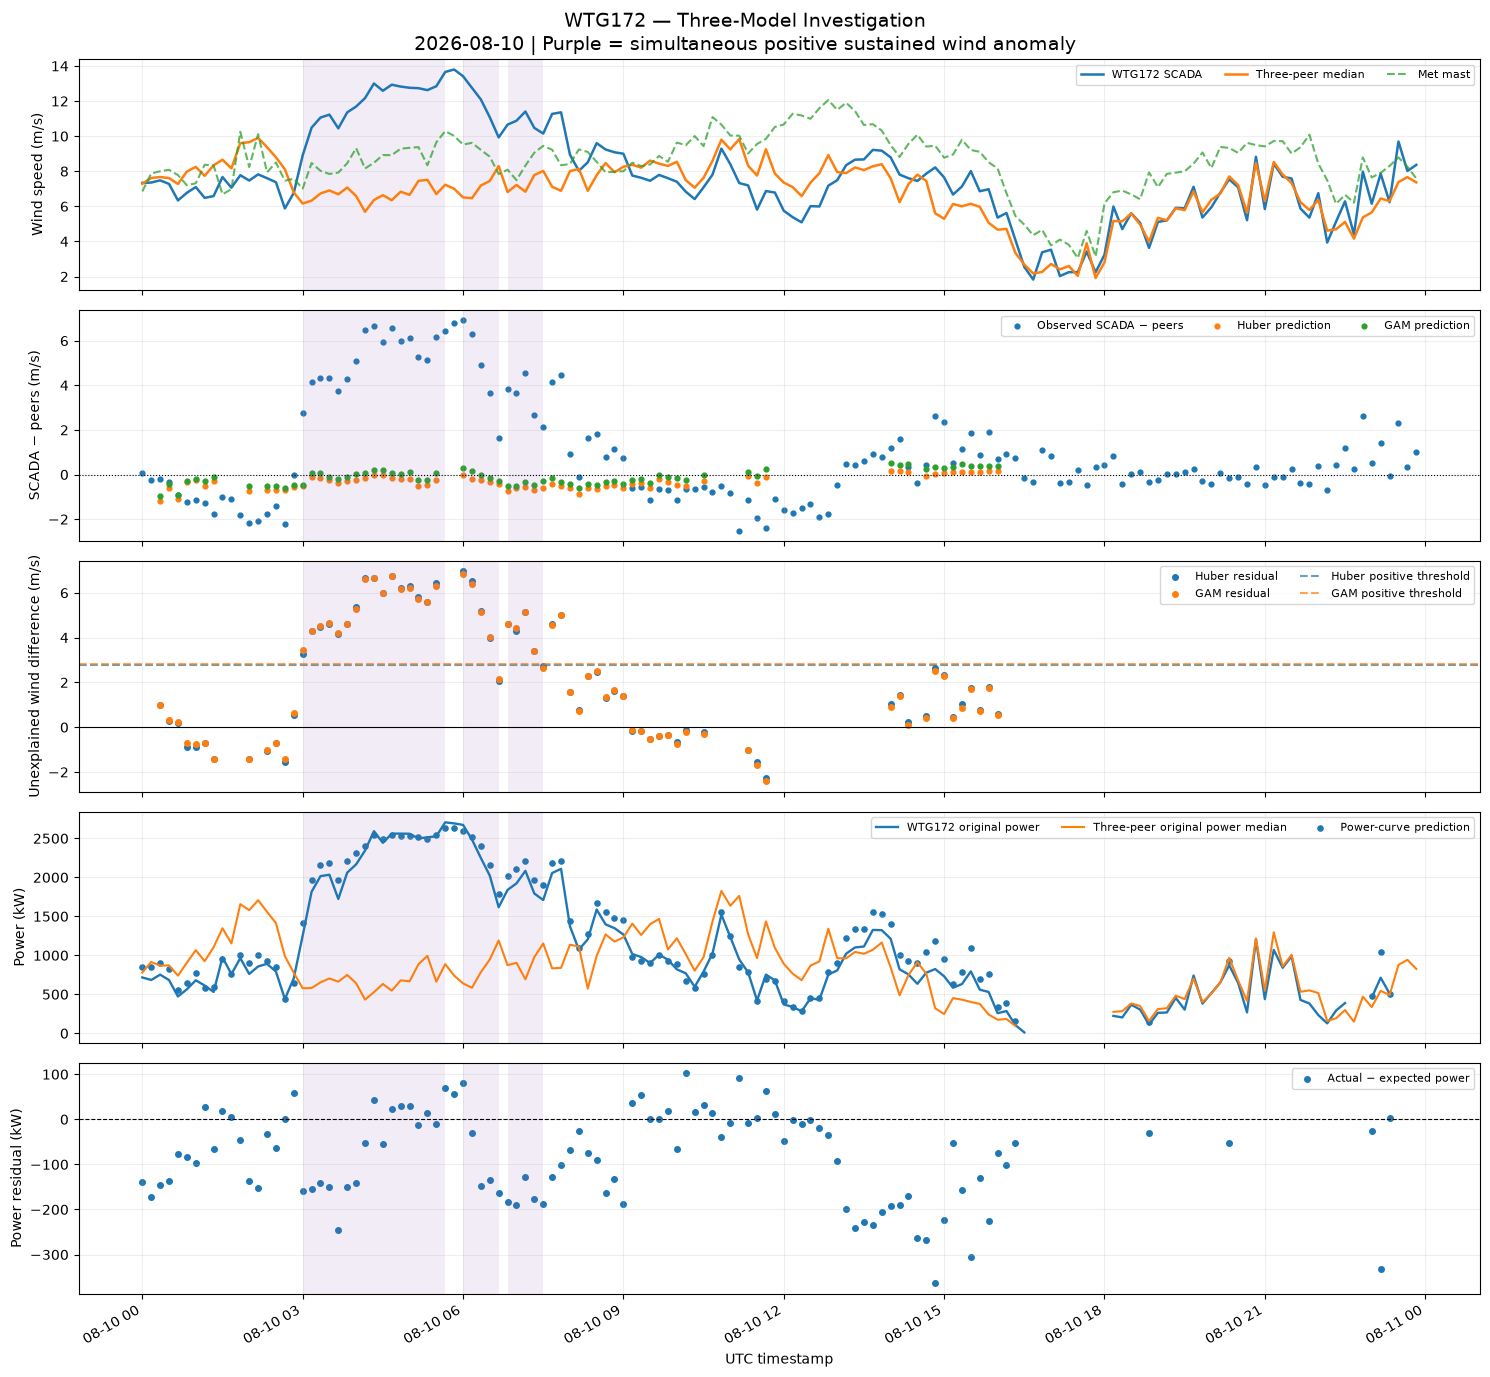

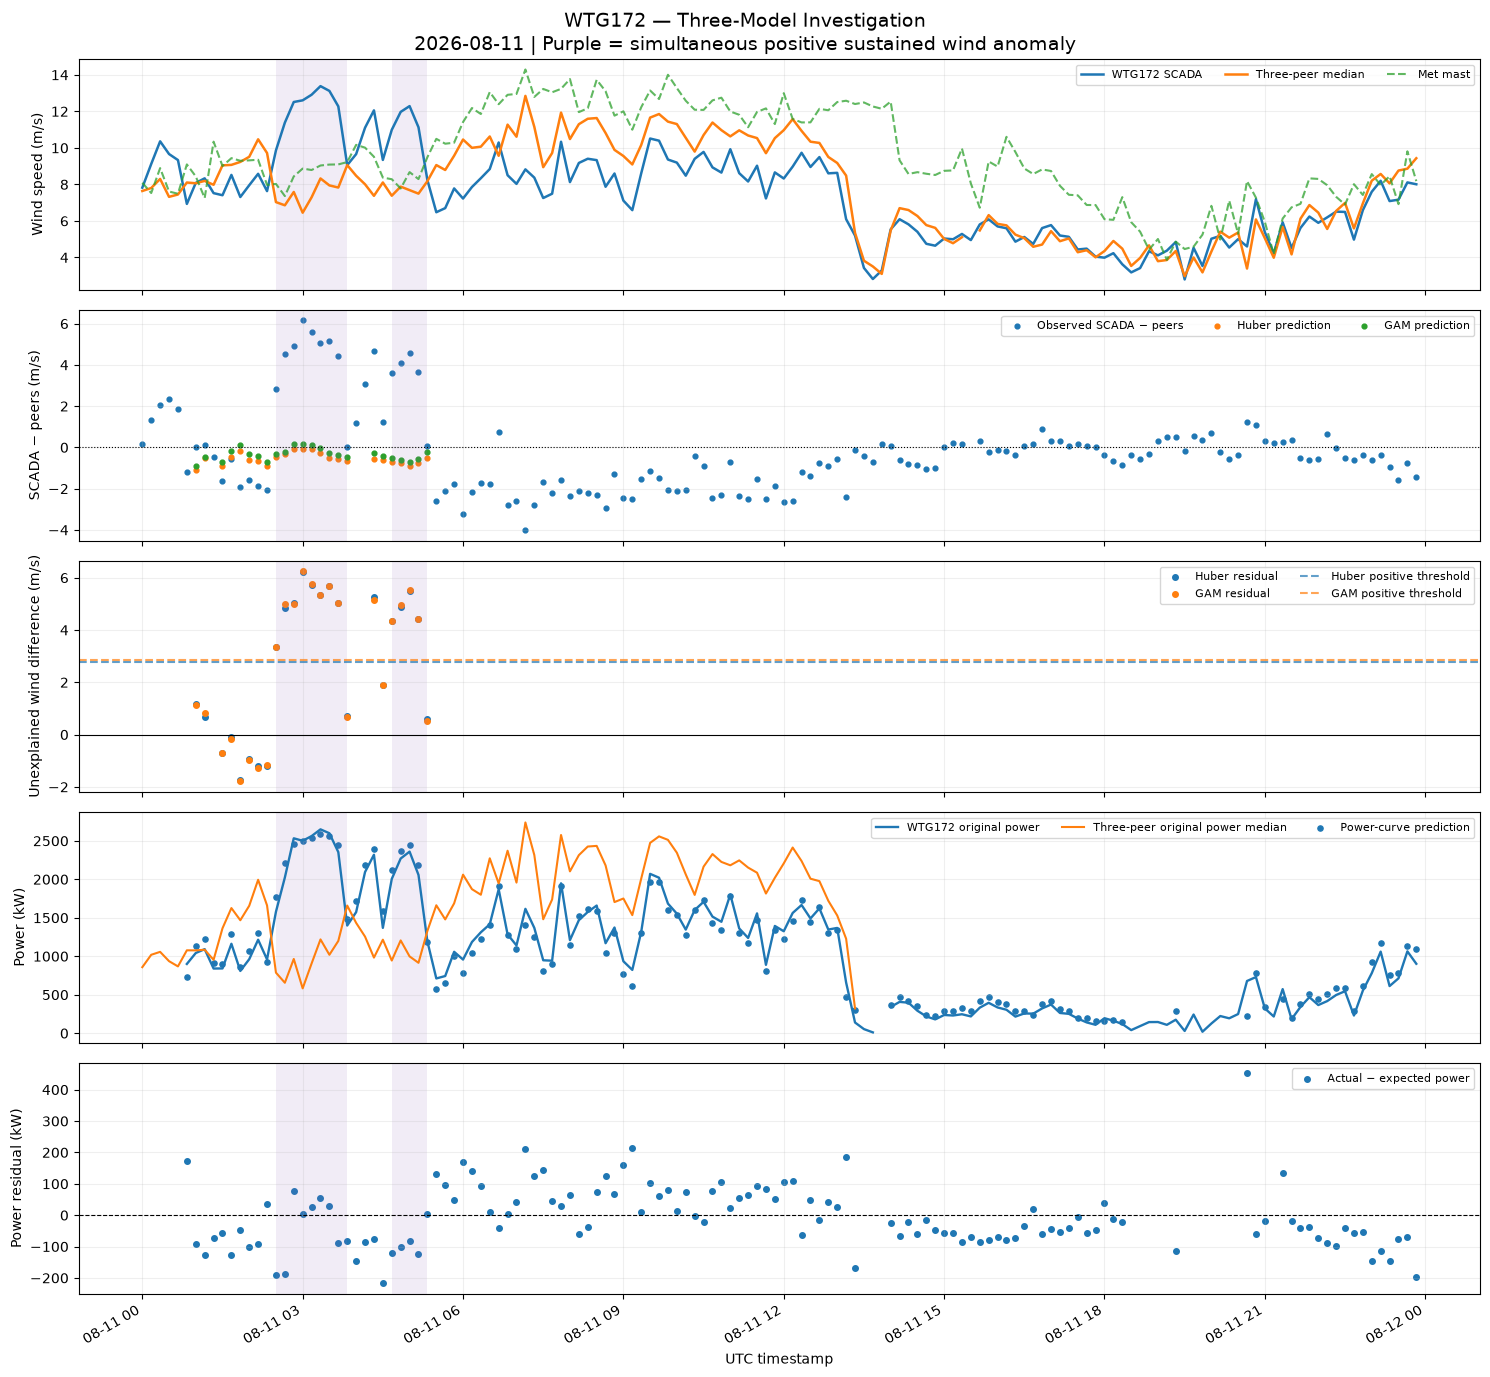

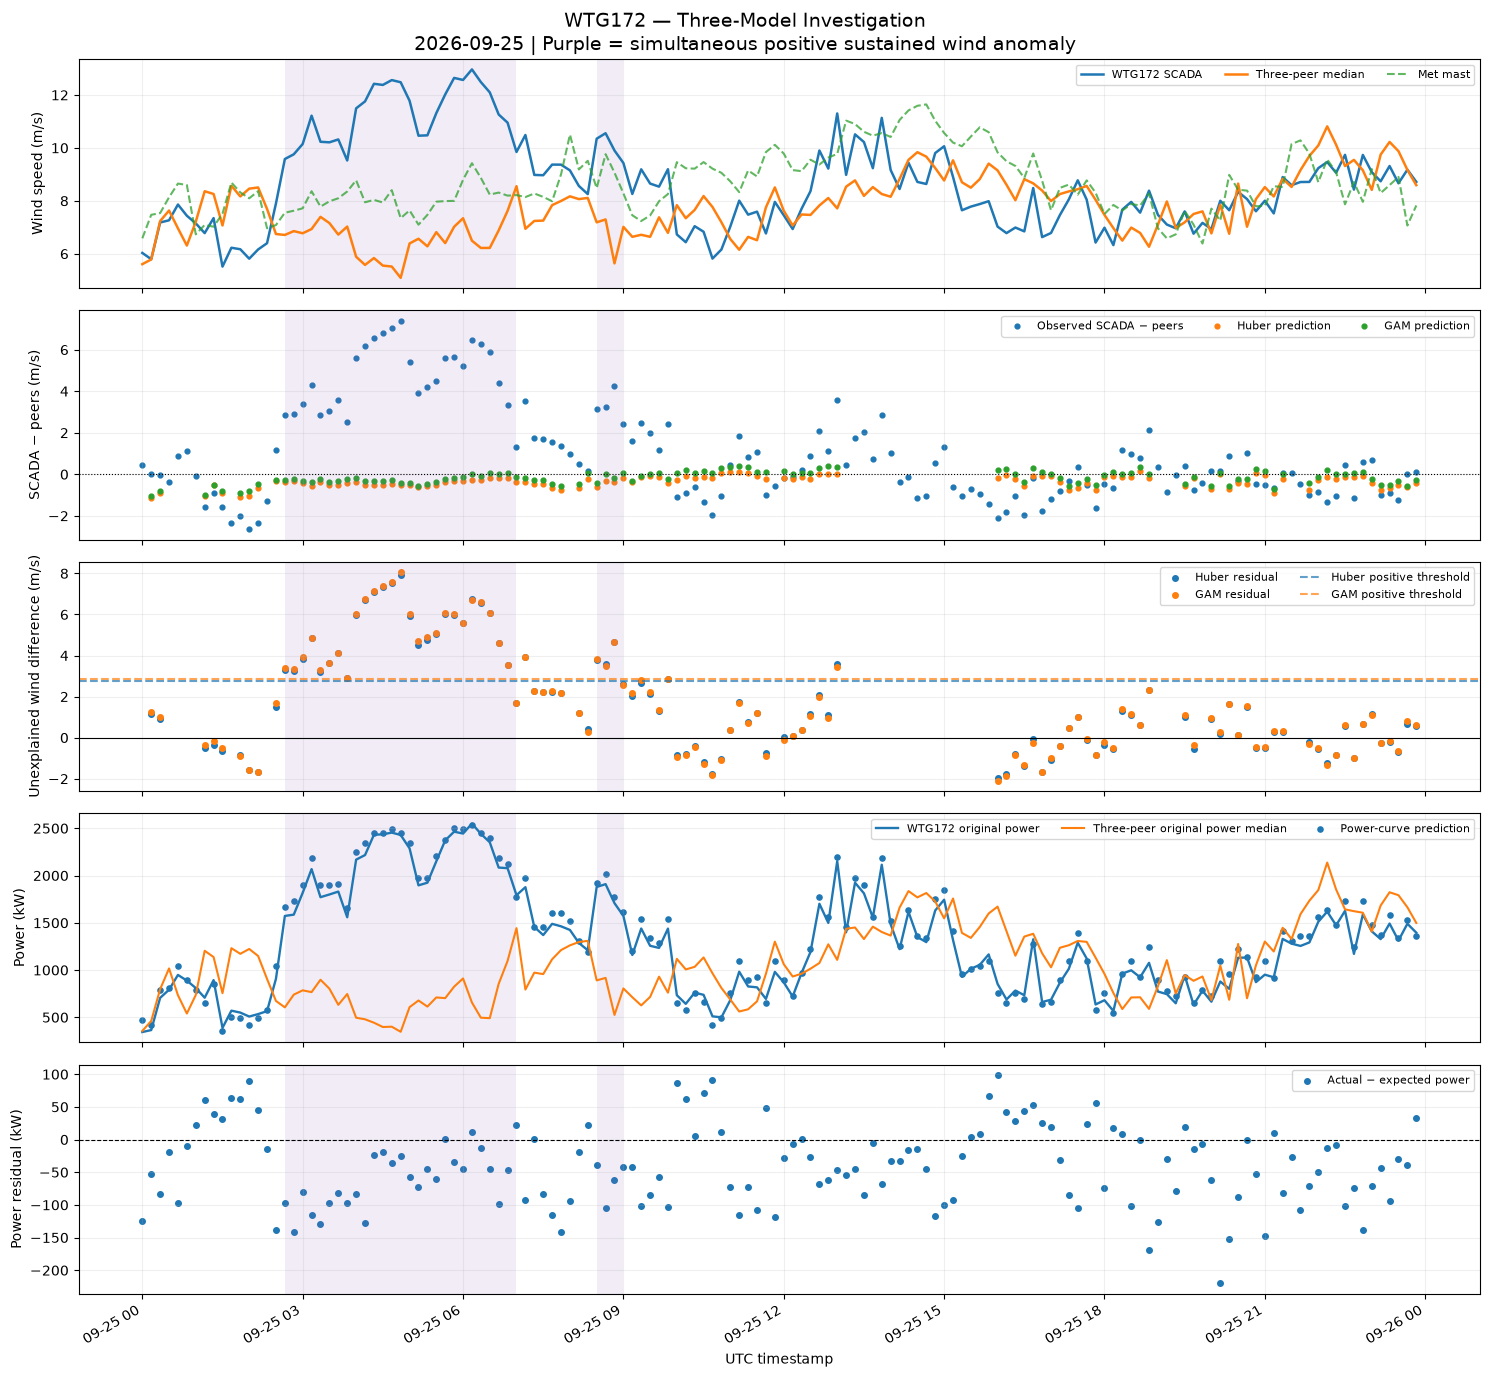


WTG172 THREE-MODEL COMPARISON COMPLETE

Files saved to:
C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\14_statistical_model_validation\WTG172_run_20261103T183320011829Z\14D_event_overlap

IMPORTANT:
- Only original real_power_ac was used.
- Missing original power remains missing.
- Wind models and power model may have different eligible timestamp sets.
- Power comparison requires target and all three peers to have generating-range measurements.
- Statistical agreement does not prove sensor failure.


In [6]:

# ============================================================
# 14D — WTG172 THREE-MODEL EVENT COMPARISON
#
# Combines:
# 1. Huber robust-regression residuals
# 2. GAM-style regression residuals
# 3. Isotonic power-curve residuals
# 4. Target and three neighboring turbines' wind speeds
# 5. Target and three neighboring turbines' ORIGINAL power
#
# Focus dates:
# August 10–11 and September 25, 2026
#
# Run AFTER Cells 14A, 14B, and 14C.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------------------
# 1. Settings and previous-model checks
# ------------------------------------------------------------

EVENT_DATES14D = [
    "2026-08-10",
    "2026-08-11",
    "2026-09-25"
]

required14D = [
    "target14",
    "p_wind14",
    "p_power14",
    "peers14",
    "robust_eval14",
    "gam_eval14",
    "power_eval14",
    "robust_summary14",
    "gam_summary14",
    "power_threshold14",
    "OUT14",
    "TARGET14",
    "SPLIT14"
]

missing14D = [
    name for name in required14D
    if name not in globals()
]

if missing14D:
    raise RuntimeError(
        "Run Cells 14A, 14B and 14C first. "
        f"Missing variables: {missing14D}"
    )

OUT14D = Path(OUT14) / "14D_event_overlap"
OUT14D.mkdir(parents=True, exist_ok=True)

if not all(
    isinstance(frame.index, pd.DatetimeIndex)
    and frame.index.is_unique
    for frame in [
        target14,
        p_wind14,
        p_power14,
        robust_eval14,
        gam_eval14,
        power_eval14
    ]
):
    raise ValueError(
        "All input tables need unique datetime indexes."
    )

print("Target turbine:", TARGET14)
print("Fixed comparison turbines:", peers14)
print("Evaluation begins:", SPLIT14)

# ------------------------------------------------------------
# 2. Combine original SCADA and peer measurements
# ------------------------------------------------------------

base14D = pd.DataFrame(
    index=target14.index
).sort_index()

base14D["target_scada_ms"] = (
    target14["wind_speed"]
)

base14D["target_original_power_kw"] = (
    target14["real_power_ac"]
)

base14D["mast_speed_ms"] = (
    target14["mast_wind_speed_ms"]
)

base14D["mast_direction_deg"] = (
    target14["mast_wind_from_deg"]
)

base14D["target_wake_category"] = (
    target14["jensen_wake_category"]
)

# Preserve each peer individually.
for peer in peers14:

    base14D[f"{peer}_wind_ms"] = (
        p_wind14[peer].reindex(base14D.index)
    )

    base14D[f"{peer}_power_kw"] = (
        p_power14[peer].reindex(base14D.index)
    )

# Median requires all three peers to be available.
base14D["peer_median_wind_ms"] = (
    p_wind14.reindex(base14D.index)
    [peers14]
    .median(axis=1, skipna=False)
)

base14D["peer_median_power_kw"] = (
    p_power14.reindex(base14D.index)
    [peers14]
    .median(axis=1, skipna=False)
)

base14D["target_minus_peers_wind_ms"] = (
    base14D.target_scada_ms
    - base14D.peer_median_wind_ms
)

# A power comparison is only considered comparable when
# target and ALL THREE peers report generating-range power.
# Missing original power stays missing.

peer_power_valid14D = (
    p_power14.reindex(base14D.index)[peers14]
    .ge(100).all(axis=1)
    &
    p_power14.reindex(base14D.index)[peers14]
    .le(2850).all(axis=1)
)

power_valid14D = (
    base14D.target_original_power_kw.between(
        100, 2850
    )
    & peer_power_valid14D
)

base14D["target_minus_peers_power_kw"] = (
    base14D.target_original_power_kw
    - base14D.peer_median_power_kw
).where(power_valid14D)

# ------------------------------------------------------------
# 3. Attach Huber regression results
# ------------------------------------------------------------

huber_cols14D = [
    "predicted_difference_ms",
    "residual_ms",
    "single_flag",
    "sustained_flag"
]

huber_part14D = robust_eval14[
    huber_cols14D
].rename(
    columns={
        "predicted_difference_ms":
            "huber_expected_difference_ms",
        "residual_ms":
            "huber_residual_ms",
        "single_flag":
            "huber_single_flag",
        "sustained_flag":
            "huber_sustained_flag"
    }
)

base14D = base14D.join(
    huber_part14D,
    how="left"
)

# ------------------------------------------------------------
# 4. Attach GAM regression results
# ------------------------------------------------------------

gam_part14D = gam_eval14[
    [
        "predicted_difference_ms",
        "residual_ms",
        "single_flag",
        "sustained_flag"
    ]
].rename(
    columns={
        "predicted_difference_ms":
            "gam_expected_difference_ms",
        "residual_ms":
            "gam_residual_ms",
        "single_flag":
            "gam_single_flag",
        "sustained_flag":
            "gam_sustained_flag"
    }
)

base14D = base14D.join(
    gam_part14D,
    how="left"
)

# ------------------------------------------------------------
# 5. Attach power-curve regression results
# ------------------------------------------------------------

power_part14D = power_eval14[
    [
        "expected_power_kw",
        "power_residual_kw",
        "unusually_low_power"
    ]
].rename(
    columns={
        "expected_power_kw":
            "model_expected_power_kw",
        "power_residual_kw":
            "model_power_residual_kw",
        "unusually_low_power":
            "model_low_power_flag"
    }
)

base14D = base14D.join(
    power_part14D,
    how="left"
)

# ------------------------------------------------------------
# 6. Identify agreement between wind-speed models
# ------------------------------------------------------------

base14D["huber_sustained"] = (
    base14D.huber_sustained_flag
    .fillna(False)
    .astype(bool)
)

base14D["gam_sustained"] = (
    base14D.gam_sustained_flag
    .fillna(False)
    .astype(bool)
)

# Both models must independently flag sustained POSITIVE
# residuals at the same timestamp.
base14D["both_models_positive_sustained"] = (
    base14D.huber_sustained
    & base14D.gam_sustained
    & base14D.huber_residual_ms.gt(0)
    & base14D.gam_residual_ms.gt(0)
)

base14D["both_models_evaluated"] = (
    base14D.huber_residual_ms.notna()
    & base14D.gam_residual_ms.notna()
)

base14D["all_three_models_evaluated"] = (
    base14D.both_models_evaluated
    & base14D.model_power_residual_kw.notna()
)

base14D["full_power_peer_comparison_available"] = (
    base14D.target_minus_peers_power_kw.notna()
)

# ------------------------------------------------------------
# 7. Extract the three suspicious event dates
# ------------------------------------------------------------

event_mask14D = (
    base14D.index.strftime("%Y-%m-%d")
    .isin(EVENT_DATES14D)
)

events14D = base14D.loc[
    event_mask14D
].copy()

events14D["event_date"] = (
    events14D.index.strftime("%Y-%m-%d")
)

flagged14D = events14D.loc[
    events14D.both_models_positive_sustained
].copy()

# ------------------------------------------------------------
# 8. Event summary
# ------------------------------------------------------------

summary_rows14D = []

for date in EVENT_DATES14D:

    x = events14D.loc[
        events14D.event_date.eq(date)
    ]

    flagged = x.loc[
        x.both_models_positive_sustained
    ]

    power_overlap = flagged.loc[
        flagged.full_power_peer_comparison_available
    ]

    model_power_overlap = flagged.loc[
        flagged.model_power_residual_kw.notna()
    ]

    summary_rows14D.append({
        "date": date,

        "scada_records": int(
            x.target_scada_ms.notna().sum()
        ),

        "huber_evaluated_n": int(
            x.huber_residual_ms.notna().sum()
        ),

        "gam_evaluated_n": int(
            x.gam_residual_ms.notna().sum()
        ),

        "both_models_positive_sustained_n":
            len(flagged),

        "mean_target_minus_peers_wind_ms":
            flagged.target_minus_peers_wind_ms.mean(),

        "mean_huber_residual_ms":
            flagged.huber_residual_ms.mean(),

        "mean_gam_residual_ms":
            flagged.gam_residual_ms.mean(),

        "original_power_available_on_flags_n": int(
            flagged.target_original_power_kw.notna().sum()
        ),

        "power_model_overlap_n":
            len(model_power_overlap),

        "mean_power_curve_residual_kw":
            model_power_overlap.model_power_residual_kw.mean(),

        "all_three_peer_power_overlap_n":
            len(power_overlap),

        "mean_target_minus_peers_power_kw":
            power_overlap.target_minus_peers_power_kw.mean(),

        "target_power_higher_than_peers_pct":
            (
                100
                * power_overlap.target_minus_peers_power_kw.gt(0).mean()
                if len(power_overlap)
                else np.nan
            )
    })

summary14D = pd.DataFrame(
    summary_rows14D
)

print("\n" + "=" * 75)
print("WTG172 — THREE-MODEL EVENT SUMMARY")
print("=" * 75)

display(summary14D.round(2))

# ------------------------------------------------------------
# 9. Display exact jointly flagged observations
# ------------------------------------------------------------

columns_to_display14D = [
    "target_scada_ms",
    "peer_median_wind_ms",
    "target_minus_peers_wind_ms",
    "huber_residual_ms",
    "gam_residual_ms",
    "target_original_power_kw",
    "peer_median_power_kw",
    "target_minus_peers_power_kw",
    "model_expected_power_kw",
    "model_power_residual_kw"
]

print("\nJOINTLY FLAGGED POSITIVE WIND-SPEED OBSERVATIONS")

display(
    flagged14D[
        columns_to_display14D
    ].head(50).round(2)
)

if flagged14D.empty:
    print(
        "No simultaneous sustained positive flags from "
        "both models on these three dates."
    )

# ------------------------------------------------------------
# 10. Create detailed event figures
# ------------------------------------------------------------

HUBER_LIMIT14D = (
    robust_summary14["exploratory_threshold_ms"]
)

GAM_LIMIT14D = (
    gam_summary14["exploratory_threshold_ms"]
)

for date in EVENT_DATES14D:

    start = pd.Timestamp(date, tz="UTC")

    # Full ten-minute grid ensures gaps remain gaps
    # rather than producing misleading diagonal lines.
    times = pd.date_range(
        start=start,
        periods=144,
        freq="10min"
    )

    day = base14D.reindex(times)

    fig, axes = plt.subplots(
        5, 1,
        figsize=(15, 14),
        sharex=True
    )

    # --------------------------------------------------------
    # Panel 1: Wind-speed comparison
    # --------------------------------------------------------

    axes[0].plot(
        times,
        day.target_scada_ms,
        label=f"{TARGET14} SCADA",
        linewidth=1.8
    )

    axes[0].plot(
        times,
        day.peer_median_wind_ms,
        label="Three-peer median",
        linewidth=1.8
    )

    axes[0].plot(
        times,
        day.mast_speed_ms,
        label="Met mast",
        linestyle="--",
        alpha=0.75
    )

    axes[0].set_ylabel("Wind speed (m/s)")
    axes[0].legend(ncol=3, fontsize=8)

    # --------------------------------------------------------
    # Panel 2: Observed vs predicted peer difference
    # --------------------------------------------------------

    axes[1].scatter(
        times,
        day.target_minus_peers_wind_ms,
        s=12,
        label="Observed SCADA − peers"
    )

    axes[1].scatter(
        times,
        day.huber_expected_difference_ms,
        s=12,
        label="Huber prediction"
    )

    axes[1].scatter(
        times,
        day.gam_expected_difference_ms,
        s=12,
        label="GAM prediction"
    )

    axes[1].axhline(
        0,
        color="black",
        linestyle=":",
        linewidth=0.8
    )

    axes[1].set_ylabel(
        "SCADA − peers (m/s)"
    )

    axes[1].legend(ncol=3, fontsize=8)

    # --------------------------------------------------------
    # Panel 3: Huber and GAM residuals
    # --------------------------------------------------------

    axes[2].scatter(
        times,
        day.huber_residual_ms,
        s=16,
        label="Huber residual"
    )

    axes[2].scatter(
        times,
        day.gam_residual_ms,
        s=16,
        label="GAM residual"
    )

    axes[2].axhline(
        HUBER_LIMIT14D,
        color="tab:blue",
        linestyle="--",
        alpha=0.7,
        label="Huber positive threshold"
    )

    axes[2].axhline(
        GAM_LIMIT14D,
        color="tab:orange",
        linestyle="--",
        alpha=0.7,
        label="GAM positive threshold"
    )

    axes[2].axhline(
        0, color="black", linewidth=0.8
    )

    axes[2].set_ylabel(
        "Unexplained wind difference (m/s)"
    )

    axes[2].legend(
        ncol=2, fontsize=8
    )

    # --------------------------------------------------------
    # Panel 4: Target and peer electrical power
    # --------------------------------------------------------

    axes[3].plot(
        times,
        day.target_original_power_kw,
        label=f"{TARGET14} original power",
        linewidth=1.7
    )

    axes[3].plot(
        times,
        day.peer_median_power_kw,
        label="Three-peer original power median",
        linewidth=1.5
    )

    axes[3].scatter(
        times,
        day.model_expected_power_kw,
        s=14,
        label="Power-curve prediction"
    )

    axes[3].set_ylabel("Power (kW)")
    axes[3].legend(ncol=3, fontsize=8)

    # --------------------------------------------------------
    # Panel 5: Power-curve residual
    # --------------------------------------------------------

    axes[4].scatter(
        times,
        day.model_power_residual_kw,
        s=16,
        label="Actual − expected power"
    )

    axes[4].axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    axes[4].set_ylabel(
        "Power residual (kW)"
    )

    axes[4].set_xlabel(
        "UTC timestamp"
    )

    axes[4].legend(fontsize=8)

    # Highlight timestamps flagged by both models.
    # Highlighting does not imply confirmed sensor fault.
    flagged_times = day.index[
        day.both_models_positive_sustained.fillna(False)
    ]

    for ax in axes:

        for t in flagged_times:

            ax.axvspan(
                t,
                t + pd.Timedelta(minutes=10),
                color="tab:purple",
                alpha=0.12,
                linewidth=0
            )

        ax.grid(alpha=0.2)

    fig.suptitle(
        f"{TARGET14} — Three-Model Investigation\n"
        f"{date} | Purple = simultaneous positive "
        "sustained wind anomaly",
        fontsize=14
    )

    fig.autofmt_xdate()
    fig.tight_layout()

    fig.savefig(
        OUT14D / f"14D_{date}_three_model_event.png",
        dpi=190,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 11. Save all results
# ------------------------------------------------------------

# Full later-period table, including non-event dates.
later14D = base14D.loc[
    base14D.index >= SPLIT14
].copy()

later14D.to_parquet(
    OUT14D / "14D_all_later_model_overlap.parquet"
)

events14D.reset_index().to_csv(
    OUT14D / "14D_event_timestamps_real_power.csv",
    index=False
)

flagged14D.reset_index().to_csv(
    OUT14D / "14D_joint_positive_wind_anomalies.csv",
    index=False
)

summary14D.to_csv(
    OUT14D / "14D_event_summary.csv",
    index=False
)

print("\n" + "=" * 75)
print("WTG172 THREE-MODEL COMPARISON COMPLETE")
print("=" * 75)

print("\nFiles saved to:")
print(OUT14D)

print(
    "\nIMPORTANT:"
    "\n- Only original real_power_ac was used."
    "\n- Missing original power remains missing."
    "\n- Wind models and power model may have different"
    " eligible timestamp sets."
    "\n- Power comparison requires target and all three"
    " peers to have generating-range measurements."
    "\n- Statistical agreement does not prove sensor failure."
)


turbine 170